## 4. Hur ser en typisk order ut?

Den här delen analyserar ordervärden: genomsnittligt ordervärde (AOV) och spridning.

- **AOV:** cirka 1 401 kr per order
- **Median:** cirka 1 089 kr, vilket är en mer typisk order
- **Spridning:** ordervärden varierar från 50 kr till 9 193 kr
- **Avvikande ordrar:** 111 ordrar (cirka 4 %) är över 3 845 kr och höjer medelvärdet
- **Datakvalitet:** inga saknade värden, inga dubbletter, och `revenue` stämmer med `price * units`

In [ ]:
#Importera de bibliotek och funktioner som analysen behöver

import pandas as pd                     # tabeller och beräkningar
import matplotlib.pyplot as plt         # figurer
import sys

# Lägg till mappen ovanför "notebooks" så att Python hittar mappen "src"
sys.path.append("..")

# Importera mina egna funktioner från src/order_metrics.py
from src.order_metrics import compute_aov, find_outliers, order_spread

# Läs in datan(varje rad är en order)
df = pd.read_csv("../data/ecommerce_sales.csv")

# Städa kolumnnamnen: ta bort mellanslag i början och slutet,
# byt mellanslag mot _ och använd små bokstäver
df.columns=(df.columns
            .str.strip()
            .str.replace(" ","_")
            .str.lower())

# Visa de första fem raderna för att se att inläsningen fungerade
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [75]:
# Visa kolumner, datatyper och antal värden som inte är tomma
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB


In [76]:
#Visa antal rader och kolumner: (rader, kolumner)
df.shape

(2500, 7)

In [77]:
# Kontrollera att order_id är unikt (True = varje rad är en egen order)
df["order_id"].is_unique

True

### Datakontroll

In [78]:
# Antal saknade värden i varje kolumn (vi vill ha 0)
print(df.isna().sum())

# Antal rader som är exakta kopior av en annan rad (vi vill ha 0)
print("Dublettrader:",df.duplicated().sum())

# Skillnaden mellan price * units och revenue för varje rad
diff = (df["price"]*df["units"] - df["revenue"]).abs()

#Antal rader där skillnaden är större än 0,01 kr (vi vill ha 0)
print("Rader där revenue inte stämmer:", (diff>0.01).sum())

order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64
Dublettrader: 0
Rader där revenue inte stämmer: 0


Datan är ren: inga saknade värden, inga dubbletter, och `revenue` stämmer med `price * units` på alla rader. Därför kan nyckeltalen nedan användas utan rensning.

In [79]:
# Beräkna genomsnittligt ordervärde (AOV) = total intäkt / antal ordrar
# Funktionen compute_aov finns i src/order_metrics.py
aov = compute_aov(df)

# Visa AOV avrundat till 2 decimaler
print(round(aov, 2))

1401.11


In [80]:
# Visa medelvärde (AOV) och median tydligt

# Medelvärdet är samma sak som AOV, eftersom varje rad är en order
print("Medelväder(AOV):", round(df["revenue"].mean(), 2), "kr")

# Medianen är mittvärdet: hälften av ordrarna ligger under det
print("Median:", round(df["revenue"].median(), 2), "kr")


Medelväder(AOV): 1401.11 kr
Median: 1088.69 kr


Varje rad är en order eftersom `order_id` är unikt, så AOV = total intäkt / antal ordrar, vilket ger cirka 1 401 kr. Medianen är lägre (cirka 1 089 kr), vilket visar att några få stora ordrar drar upp snittet. Medianen beskriver därför en typisk order bättre än AOV.

In [81]:
# Sammanfatta spridningen: antal, medelvärde, standardavvikelse,
# min, kvartiler (25 %, 50 %, 75 %) och max
# Funktionen order_spread finns i src/order_metrics.py

order_spread(df)

count    2500.00
mean     1401.11
std      1166.94
min        50.00
25%       577.96
50%      1088.69
75%      1884.75
max      9192.60
Name: revenue, dtype: float64

In [82]:
# Räkna ut gränsen för ovanligt stora ordrar med IQR-regeln:
# övre gräns = Q3 + 1,5 * (Q3 - Q1)
q1 = df["revenue"].quantile(0.25)
q3 = df["revenue"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

# Hämta de avvikande ordrarna med funktionen från src/order_metrics.py
outliers = find_outliers(df)

print("Övre gräns (kr):",round(upper_limit,2))
print("Antal avvikande ordrar:",len(outliers))
print("Andel av alla ordrar:",round(len(outliers) / len(df)*100, 1), "%")

Övre gräns (kr): 3844.94
Antal avvikande ordrar: 111
Andel av alla ordrar: 4.4 %


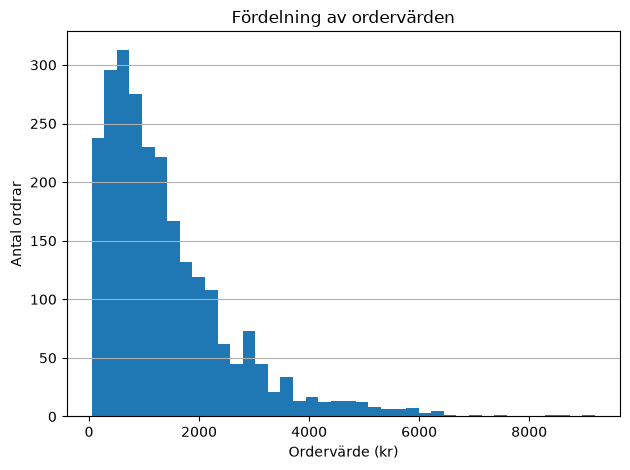

In [83]:
# Rita histogram över ordervärden (40 staplar, varje stapel är ett prisintervall)
fig, ax = plt.subplots()

# Titel och axeltext
ax.hist(df["revenue"].dropna(), bins = 40)
ax.set_title("Fördelning av ordervärden")
ax.set_xlabel("Ordervärde (kr)")
ax.set_ylabel("Antal ordrar")

# Horisontella hjälplinjer gör det lättare att läsa av antalet
ax.grid(True, axis = "y")

# Justera marginalerna så att inget klipps bort, och visa figuren
plt.tight_layout()
plt.show()

Histogrammet visar fördelningen av ordervärden. De flesta ordrar ligger mellan 0 och 2 000 kr, och de vanligaste värdena ligger kring 500 till 800 kr. Den långa svansen åt höger visar att ett fåtal mycket stora ordrar höjer medelvärdet (AOV) över medianen.

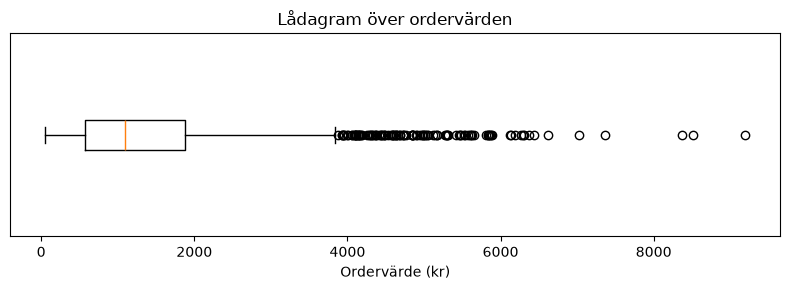

In [84]:
# Rita lådagram (boxplot) över ordervärden, liggande
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot(df["revenue"], orientation = "horizontal")

# Titel och axeltext
ax.set_title("Lådagram över ordervärden")
ax.set_xlabel("Ordervärde (kr)")

# Ta bort den onödiga siffran på y-axeln
ax.set_yticks([])

# Justera marginalerna och visa figuren
plt.tight_layout()
plt.show()

Lådagrammet visar att hälften av alla ordrar ligger mellan cirka 580 och 1 900 kr, med medianen på cirka 1 090 kr. Prickarna till höger är de 111 ovanligt stora ordrarna (över 3 845 kr).

### Rekommendation (fråga 4)

- Använd medianen (cirka 1 089 kr) som mått på en typisk order, och redovisa AOV (cirka 1 401 kr) tillsammans med den. Några få stora ordrar (över 3 845 kr, cirka 4 % av ordrarna) höjer snittet, så AOV ensamt ger en för hög bild av vad en vanlig kund köper.